# Evaluation Metrics — Python companion
**GSND 5355Q [Machine Learning for Biomedical Data](https://njms.rutgers.edu/sgs/olc/mlbd/index.php), Week 1**

This notebook follows the R lecture `lectures/week2/evaluationMetrics.Rmd` section by section, using `pandas`, `scikit-learn`, and `matplotlib` in place of `tidyverse` and `caret`.

> **Note:** Python and R use different random number generators, so splits, resamples, and some numbers below will differ slightly from the R slides. The ideas and conclusions are the same.

## Evaluation metrics
We'll predict sex from height using the `heights` data from the R `dslabs` package (exported to CSV for this course).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data live in python/data/ in the course repo. If you're running this
# notebook somewhere else (e.g., Google Colab), it falls back to GitHub.
LOCAL = "../data/"
REMOTE = "https://raw.githubusercontent.com/wevanjohnson/2026_Fall_MLBD/main/python/data/"
DATA = LOCAL if os.path.exists(LOCAL) else REMOTE

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

heights = pd.read_csv(DATA + "heights.csv")
heights["sex"] = pd.Categorical(heights["sex"], categories=["Female", "Male"])
heights.head()

,sex,height
0,Male,75.0
1,Male,70.0
2,Male,68.0
3,Male,74.0
4,Male,61.0


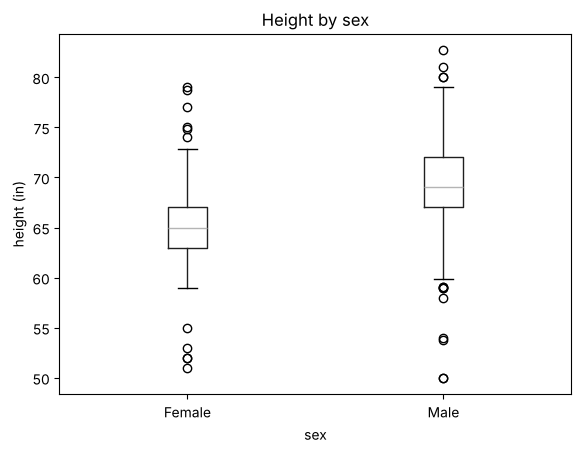

In [2]:
heights.boxplot(column="height", by="sex", grid=False)
plt.suptitle(""); plt.title("Height by sex"); plt.ylabel("height (in)")
plt.show()

In [3]:
y = heights["sex"]
x = heights["height"]

## Training and test sets
`caret::createDataPartition` makes a split that is balanced on the outcome. In scikit-learn, `train_test_split` with `stratify=y` does the same.

In [4]:
train_set, test_set = train_test_split(heights, test_size=0.5, stratify=y, random_state=2007)
len(train_set), len(test_set)

(525, 525)

## Overall accuracy
Start with the simplest possible algorithm: guess the outcome at random.

In [5]:
rng = np.random.default_rng(2007)
y_hat = rng.choice(["Male", "Female"], size=len(test_set), replace=True)
np.mean(y_hat == test_set["sex"])

np.float64(0.5238095238095238)

Not surprisingly, about 50%. Can we do better? Males are slightly taller on average:

In [6]:
heights.groupby("sex", observed=True)["height"].agg(["mean", "std"])

,mean,std
sex,,
Female,64.939424,3.760656
Male,69.314755,3.611024


Predict *Male* if height is within two SDs of the average male (i.e., > 62 inches):

In [7]:
y_hat = np.where(x > 62, "Male", "Female")
np.mean(y == y_hat)

np.float64(0.7933333333333333)

Choose the cutoff that maximizes accuracy **on the training set** (never the test set):

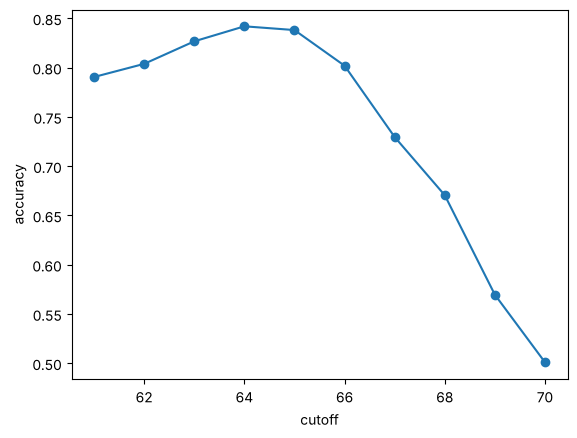

In [8]:
cutoff = np.arange(61, 71)
accuracy = [np.mean(np.where(train_set["height"] > c, "Male", "Female") == train_set["sex"])
            for c in cutoff]

plt.plot(cutoff, accuracy, "o-")
plt.xlabel("cutoff"); plt.ylabel("accuracy")
plt.show()

In [9]:
max(accuracy)

np.float64(0.8419047619047619)

In [10]:
best_cutoff = cutoff[int(np.argmax(accuracy))]
best_cutoff

np.int64(64)

Now evaluate that cutoff on the held-out test set:

In [11]:
y_hat = np.where(test_set["height"] > best_cutoff, "Male", "Female")
accuracy_score(test_set["sex"], y_hat)

0.8114285714285714

## The confusion matrix

In [12]:
pd.crosstab(pd.Series(y_hat, name="predicted"), test_set["sex"].reset_index(drop=True).rename("actual"))

actual,Female,Male
predicted,,
Female,49,29
Male,70,377


Accuracy broken down by sex shows the problem: females are predicted poorly.

In [13]:
(test_set.assign(correct=(y_hat == test_set["sex"]))
          .groupby("sex", observed=True)["correct"].mean())

sex
Female    0.411765
Male      0.928571
Name: correct, dtype: float64

In [14]:
prev = np.mean(y == "Male")
prev

np.float64(0.7733333333333333)

## Sensitivity and specificity

|                    | Actually positive    | Actually negative    |
|--------------------|----------------------|----------------------|
| Predicted positive | True positives (TP)  | False positives (FP) |
| Predicted negative | False negatives (FN) | True negatives (TN)  |

- **Sensitivity** (recall, TPR) = TP / (TP + FN)
- **Specificity** (TNR) = TN / (TN + FP)
- **Precision** (PPV) = TP / (TP + FP)

`caret::confusionMatrix` treats the **first factor level** (here, *Female*) as the positive class, so we do the same. scikit-learn has no built-in specificity, so we compute it from the confusion matrix.

In [15]:
labels = ["Female", "Male"]          # positive class first, as in caret
cm = confusion_matrix(test_set["sex"], y_hat, labels=labels)
tp, fn, fp, tn = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]

print(pd.DataFrame(cm, index=["actual Female", "actual Male"],
                   columns=["pred Female", "pred Male"]))
print()
print(f"Accuracy:    {(tp + tn) / cm.sum():.3f}")
print(f"Sensitivity: {tp / (tp + fn):.3f}")
print(f"Specificity: {tn / (tn + fp):.3f}")
print(f"Prevalence:  {(tp + fn) / cm.sum():.3f}")

               pred Female  pred Male
actual Female           49         70
actual Male             29        377

Accuracy:    0.811
Sensitivity: 0.412
Specificity: 0.929
Prevalence:  0.227


`classification_report` gives per-class precision and recall. Note that the *recall* for Male equals the specificity above.

In [16]:
print(classification_report(test_set["sex"], y_hat, labels=labels, digits=3))

              precision    recall  f1-score   support

      Female      0.628     0.412     0.497       119
        Male      0.843     0.929     0.884       406

    accuracy                          0.811       525
   macro avg      0.736     0.670     0.691       525
weighted avg      0.795     0.811     0.796       525



## Application: a blood biomarker for tuberculosis
Blood expression of 107 TB-related genes in 179 people with active TB or latent TB infection (LTBI) (Kaipilyawar et al., *Clin Infect Dis*, 2022). We build the Sweeney et al. (2016) 3-gene score, $(\text{GBP5} + \text{DUSP3})/2 - \text{KLF2}$.

(179, 109)
TB_Status
LTBI    100
TB       79
Name: count, dtype: int64


/tmp/ipykernel_862/3940323665.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tb = tb.assign(score=(tb["GBP5"] + tb["DUSP3"]) / 2 - tb["KLF2"])


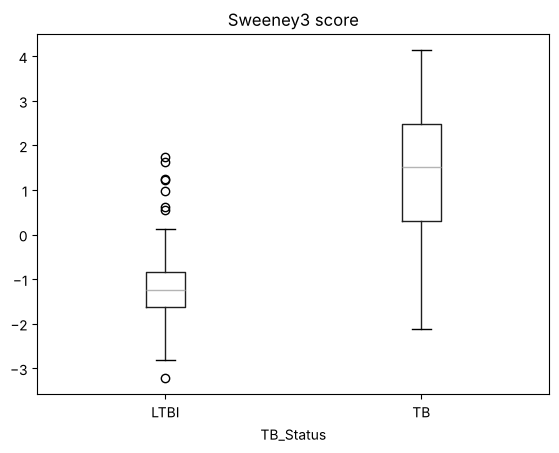

In [17]:
tb = pd.read_csv(DATA + "TBnanostring.csv")
tb["TB_Status"] = pd.Categorical(tb["TB_Status"], categories=["LTBI", "TB"])
tb = tb.assign(score=(tb["GBP5"] + tb["DUSP3"]) / 2 - tb["KLF2"])
print(tb.shape); print(tb["TB_Status"].value_counts())
tb.boxplot(column="score", by="TB_Status", grid=False)
plt.suptitle(""); plt.title("Sweeney3 score"); plt.show()

## Choosing a cutoff for the intended use
WHO target for a TB triage test: sensitivity ≥ 90%, specificity ≥ 70%. Pick the cutoff that catches 90% of TB cases in the training set, then check it on the test set. With only ~24 TB cases in the test set, test sensitivity is noisy and can miss the target (the R slides got 0.87 with a different split).

In [18]:
tb_train, tb_test = train_test_split(tb, test_size=0.3, stratify=tb["TB_Status"], random_state=1)
cut = tb_train.loc[tb_train["TB_Status"] == "TB", "score"].quantile(0.10)
pred = np.where(tb_test["score"] > cut, "TB", "LTBI")
cm_tb = confusion_matrix(tb_test["TB_Status"], pred, labels=["TB", "LTBI"])
tp, fn, fp, tn = cm_tb.ravel()
sens, spec = tp / (tp + fn), tn / (tn + fp)
print(pd.DataFrame(cm_tb, index=["actual TB", "actual LTBI"], columns=["pred TB", "pred LTBI"]))
print(f"sensitivity {sens:.3f}  specificity {spec:.3f}")

             pred TB  pred LTBI
actual TB         18          6
actual LTBI        1         29
sensitivity 0.750  specificity 0.967


## ROC curve and AUC
The ROC curve shows sensitivity vs. 1 − specificity across all cutoffs; the AUC is the probability that a random TB case scores higher than a random LTBI case. (`pROC::roc` in R; `roc_curve` and `roc_auc_score` here.)

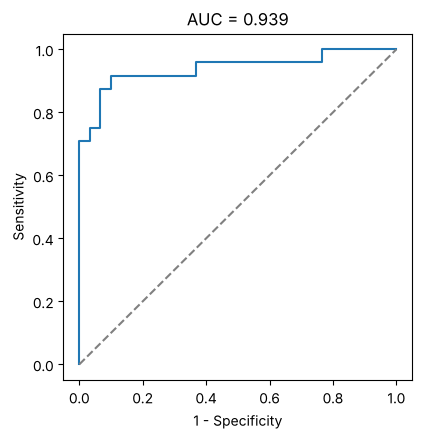

In [19]:
from sklearn.metrics import roc_curve, roc_auc_score
y_test_tb = (tb_test["TB_Status"] == "TB").astype(int)
fpr, tpr, _ = roc_curve(y_test_tb, tb_test["score"])
auc_tb = roc_auc_score(y_test_tb, tb_test["score"])
plt.figure(figsize=(4.5, 4.5))
plt.plot(fpr, tpr); plt.plot([0, 1], [0, 1], ls="--", color="grey")
plt.xlabel("1 - Specificity"); plt.ylabel("Sensitivity"); plt.title(f"AUC = {auc_tb:.3f}")
plt.show()

## Prevalence changes predictive values
PPV depends on how common TB is in the people tested. (The split differs from R's, so the numbers differ a little from the slides.)

In [20]:
ppv = lambda prev: sens * prev / (sens * prev + (1 - spec) * (1 - prev))
pd.Series({"study (44%)": ppv(0.44), "clinic (10%)": ppv(0.10), "screening (1%)": ppv(0.01)}).round(3)

study (44%)       0.946
clinic (10%)      0.714
screening (1%)    0.185
dtype: float64

## Session info

In [21]:
import sys, sklearn, matplotlib
print("Python", sys.version.split()[0])
print("numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.18
numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | matplotlib 3.11.2
